# Bài 5 · Biểu diễn từ bằng vector (Word Embeddings)

**Thời lượng gợi ý:** 150 phút · **Cần:** Bài 2, Bài 4 · **Dùng PyTorch trên CPU**

## Mục tiêu

1. Hiểu **giả thuyết phân bố**: *"hiểu một từ qua những từ đi cùng nó"*.
2. Xây embedding từ **ma trận đồng xuất hiện → PPMI → SVD**, hoàn toàn bằng NumPy.
3. Cài đặt **Skip-gram với negative sampling** (Word2Vec) bằng PyTorch từ đầu.
4. Dùng độ tương tự cosine để tìm từ lân cận, và hiểu embedding bắt được gì, **không** bắt được gì (đồng nghĩa ≠ cùng ngữ cảnh).
5. Dùng embedding làm đặc trưng cho phân loại, và so với TF-IDF một cách trung thực.

> **Thành thật về quy mô.** Kho của ta chỉ ~11 nghìn token. Word2Vec thật sự cần hàng trăm triệu token. Mục tiêu bài này là hiểu *cơ chế*; chất lượng embedding ở đây chỉ đủ để thấy xu hướng, không dùng làm sản phẩm. Ở Bài 9–12, bạn sẽ dùng mô hình tiền huấn luyện thật.

In [1]:
import sys, pathlib

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

from nlpvi import load_splits, normalize, segment, split_sentences, set_seed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
set_seed(42)
train, valid, test = load_splits()

## 1. Vì sao one-hot là chưa đủ?

Ở Bài 2, mỗi từ là một chiều riêng (one-hot). Hai từ bất kỳ đều **vuông góc**: cosine("nhanh", "mau") = cosine("nhanh", "đắt") = 0. Vector one-hot không chứa chút thông tin nào về quan hệ nghĩa, và nó rất thưa/chiều cao.

**Embedding**: mỗi từ là một vector *dày, chiều thấp* (vài chục đến vài trăm chiều), sao cho từ có vai trò giống nhau có vector gần nhau.

> *"You shall know a word by the company it keeps."* — J. R. Firth (1957)

Từ nào xuất hiện trong các **ngữ cảnh** giống nhau thì có nghĩa/vai trò tương tự. Ta cần một cách biến "ngữ cảnh" thành con số.

## 2. Chuẩn bị kho văn bản

Dùng lại cách xử lý ở Bài 4: tách câu → tách từ → chữ thường; từ chỉ xuất hiện 1 lần bị bỏ khỏi từ điển.

In [2]:
def cau_thanh_tu(text):
    out = []
    for cau in split_sentences(normalize(text, emoji="drop", expand_teencode=True)):
        toks = [w for w in segment(cau).split() if any(ch.isalnum() for ch in w)]
        if toks:
            out.append(toks)
    return out

sents = [s for t in train["text"] for s in cau_thanh_tu(t)]
dem = Counter(w for s in sents for w in s)
tu_dien = sorted(w for w, c in dem.items() if c >= 3)       # chỉ giữ từ có ≥ 3 lần xuất hiện
w2i = {w: i for i, w in enumerate(tu_dien)}
V = len(tu_dien)
ids = [[w2i[w] for w in s if w in w2i] for s in sents]
ids = [s for s in ids if len(s) >= 2]
print(f"{len(sents)} câu · từ điển V = {V} · {sum(map(len, ids))} token sau lọc")

2254 câu · từ điển V = 423 · 10761 token sau lọc


## 3. Cách 1: đồng xuất hiện → PPMI → SVD

### 3.1 Ma trận đồng xuất hiện

Với mỗi từ trung tâm, đếm các từ xuất hiện trong **cửa sổ** ±*w* xung quanh. Ta cho các từ gần trọng số lớn hơn (1/khoảng cách).

In [3]:
WINDOW = 3
C = np.zeros((V, V))
for s in ids:
    for i, w in enumerate(s):
        for j in range(max(0, i - WINDOW), min(len(s), i + WINDOW + 1)):
            if i != j:
                C[w, s[j]] += 1.0 / abs(i - j)
print("Hình dạng:", C.shape, "| mật độ ô khác 0:", f"{(C > 0).mean():.1%}")

Hình dạng: (423, 423) | mật độ ô khác 0: 4.6%


### 3.2 Từ đếm thô đến PPMI

Đếm thô bị chi phối bởi từ phổ biến ("không", "rất"...). **Pointwise Mutual Information** đo mức "hai từ đi cùng nhau *nhiều hơn mức ngẫu nhiên*":

$$\text{PMI}(w,c)=\log\frac{P(w,c)}{P(w)\,P(c)},\qquad \text{PPMI}=\max(\text{PMI},0)$$

Ta làm mịn phân phối ngữ cảnh $P(c)\propto \text{count}(c)^{0{,}75}$ (mẹo của Word2Vec, giúp ưu ái từ hiếm).

In [4]:
tong = C.sum()
p_wc = C / tong
p_w = C.sum(axis=1, keepdims=True) / tong
c_mu = C.sum(axis=0) ** 0.75
p_c = (c_mu / c_mu.sum())[None, :]

with np.errstate(divide="ignore", invalid="ignore"):
    pmi = np.log(p_wc / (p_w * p_c))
ppmi = np.where(np.isfinite(pmi) & (pmi > 0), pmi, 0.0)

# SVD cắt cụt: giữ d chiều lớn nhất → embedding dày
D = 32
U, S, Vt = np.linalg.svd(ppmi, full_matrices=False)
E_svd = U[:, :D] * np.sqrt(S[:D])
print("Embedding SVD:", E_svd.shape, "| phương sai giữ lại:", f"{(S[:D]**2).sum() / (S**2).sum():.1%}")

Embedding SVD: (423, 32) | phương sai giữ lại: 46.8%


### 3.3 Láng giềng gần nhất

In [5]:
def chuan_hoa(E):
    return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)

def lang_gieng(E, tu, k=6):
    if tu not in w2i:
        return None
    En = chuan_hoa(E)
    sim = En @ En[w2i[tu]]
    top = sim.argsort()[::-1][1:k + 1]
    return [(tu_dien[i], round(float(sim[i]), 2)) for i in top]

for t in ["nhanh", "chậm", "đắt", "nhân_viên", "ứng_dụng", "không"]:
    kq = lang_gieng(E_svd, t)
    if kq:
        print(f"{t:10s} →", ", ".join(f"{w} ({s})" for w, s in kq))

nhanh      → khiếu_nại (0.71), thân_thiện (0.69), qua_loa (0.68), chuyên_nghiệp (0.65), chu_đáo (0.65), đáng (0.65)
chậm       → thừa_thãi (0.87), xấu (0.84), rối (0.83), rườm_rà (0.82), thấp (0.82), thiếu (0.81)
đắt        → ôi (0.89), sơ_sài (0.88), thô (0.87), thấp (0.84), ẩu (0.82), xấu (0.82)
nhân_viên  → chuyên_nghiệp (0.85), mập_mờ (0.83), việc (0.8), khiếu_nại (0.79), hướng_dẫn (0.78), của (0.75)
ứng_dụng   → lỗi (0.87), ít (0.81), các (0.8), hệ_thống (0.79), đủ (0.78), chức_năng (0.76)
không      → lại (0.88), ủng_hộ (0.86), tiếp (0.86), sẽ (0.82), khuyên (0.82), lắm (0.82)


**Đọc kết quả cẩn thận (số của bạn có thể lệch nhẹ).** Với SVD-PPMI, "chậm" có láng giềng là toàn các tính từ chê (*thừa thãi, xấu, rối, rườm rà, thiếu*), còn "nhanh" có láng giềng là các tính từ về chất lượng dịch vụ **lẫn lộn cả khen lẫn chê** (*thân thiện, chuyên nghiệp, chu đáo* nhưng cũng *qua loa*). Bảng cosine bên dưới còn cho thấy điều đáng ngạc nhiên: cos(nhanh, chậm) ≈ 0,5 — **cao hơn** cos(nhanh, tốt) ≈ 0,35. Trái nghĩa gần nhau *hơn* cả đồng nghĩa-theo-cảm-xúc! Sang mục 4 bạn sẽ thấy Skip-gram xếp "chậm" là láng giềng **gần nhất** của "nhanh" (và ngược lại).

Lý do: trái nghĩa đi vào **cùng ngữ cảnh** ("giao hàng *nhanh*" / "giao hàng *chậm*"). Embedding đo **khả năng thay thế trong ngữ cảnh**, không đo đồng nghĩa, và chỉ gián tiếp đo cảm xúc. Đây là hạn chế quan trọng khi dùng embedding cho phân tích cảm xúc.

In [6]:
def cos(E, a, b):
    En = chuan_hoa(E)
    return float(En[w2i[a]] @ En[w2i[b]])

cap = [("nhanh", "chậm"), ("nhanh", "tốt"), ("chậm", "kém"), ("đắt", "rẻ"), ("đắt", "cao")]
cap = [(a, b) for a, b in cap if a in w2i and b in w2i]
pd.DataFrame([{"cặp": f"{a} – {b}", "cosine (SVD)": round(cos(E_svd, a, b), 3)} for a, b in cap])

,cặp,cosine (SVD)
0,nhanh – chậm,0.505
1,nhanh – tốt,0.346
2,chậm – kém,0.531
3,đắt – rẻ,0.464
4,đắt – cao,0.495


## 4. Cách 2: Skip-gram với negative sampling (Word2Vec)

Thay vì đếm rồi phân rã, ta **huấn luyện** một mô hình nhỏ làm nhiệm vụ giả: *cho từ trung tâm $w$, đoán từ ngữ cảnh $c$*. Embedding là sản phẩm phụ của quá trình đó.

Với mỗi cặp thật $(w,c)$ và $K$ cặp âm $(w,n_k)$ lấy ngẫu nhiên, ta tối thiểu hóa:

$$\mathcal{L}=-\log\sigma(\mathbf{u}_w\!\cdot\!\mathbf{v}_c)-\sum_{k=1}^{K}\log\sigma(-\mathbf{u}_w\!\cdot\!\mathbf{v}_{n_k})$$

Nghĩa là: kéo vector từ trung tâm lại gần ngữ cảnh *thật*, đẩy ra xa ngữ cảnh *ngẫu nhiên*. Từ âm được lấy theo phân phối tần suất$^{0{,}75}$.

In [7]:
# 1) Sinh các cặp (trung tâm, ngữ cảnh)
cap_tc = [(s[i], s[j]) for s in ids for i in range(len(s))
          for j in range(max(0, i - 2), min(len(s), i + 3)) if i != j]
cap_tc = torch.tensor(cap_tc)
print("Số cặp huấn luyện:", len(cap_tc))

# 2) Phân phối lấy mẫu âm
tan_suat = np.array([dem[w] for w in tu_dien], dtype=float) ** 0.75
p_neg = torch.tensor(tan_suat / tan_suat.sum(), dtype=torch.float)

class SkipGram(nn.Module):
    def __init__(self, V, d):
        super().__init__()
        self.u = nn.Embedding(V, d)     # vector khi làm từ trung tâm  → đây là embedding ta giữ
        self.v = nn.Embedding(V, d)     # vector khi làm ngữ cảnh
        nn.init.uniform_(self.u.weight, -0.5 / d, 0.5 / d)
        nn.init.zeros_(self.v.weight)

    def forward(self, w, c, neg):
        uw = self.u(w)                                   # (B, d)
        pos = F.logsigmoid((uw * self.v(c)).sum(-1))     # (B)
        neg_s = torch.bmm(self.v(neg), uw.unsqueeze(2)).squeeze(2)   # (B, K)
        return -(pos + F.logsigmoid(-neg_s).sum(-1)).mean()

Số cặp huấn luyện: 29724


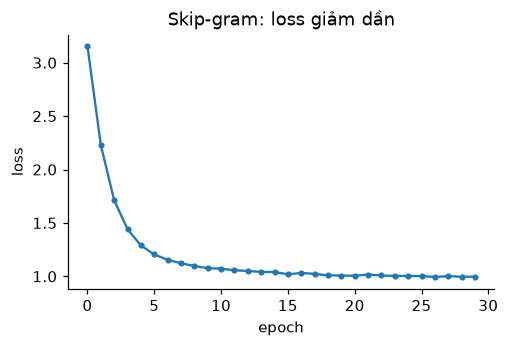

In [8]:
set_seed(0)
model = SkipGram(V, D)
opt = torch.optim.Adam(model.parameters(), lr=0.01)
K, BATCH, EPOCHS = 5, 512, 30

loss_hist = []
for ep in range(EPOCHS):
    perm = torch.randperm(len(cap_tc))
    tong_loss = 0.0
    for b in range(0, len(perm), BATCH):
        batch = cap_tc[perm[b:b + BATCH]]
        neg = torch.multinomial(p_neg, len(batch) * K, replacement=True).view(len(batch), K)
        loss = model(batch[:, 0], batch[:, 1], neg)
        opt.zero_grad(); loss.backward(); opt.step()
        tong_loss += loss.item() * len(batch)
    loss_hist.append(tong_loss / len(cap_tc))

plt.figure(figsize=(5, 3)); plt.plot(loss_hist, marker="."); plt.xlabel("epoch"); plt.ylabel("loss")
plt.title("Skip-gram: loss giảm dần"); plt.show()
E_w2v = model.u.weight.detach().numpy()

In [9]:
print("=== láng giềng theo Skip-gram ===")
for t in ["nhanh", "chậm", "đắt", "nhân_viên", "ứng_dụng", "không"]:
    kq = lang_gieng(E_w2v, t)
    if kq:
        print(f"{t:10s} →", ", ".join(f"{w} ({s})" for w, s in kq))

=== láng giềng theo Skip-gram ===
nhanh      → chậm (0.69), qua_loa (0.66), thoải_mái (0.64), chu_đáo (0.63), gọn_gàng (0.63), nhiệt_tình (0.62)
chậm       → nhanh (0.69), trễ (0.67), qua_loa (0.67), giật (0.67), rườm_rà (0.67), lâu (0.65)
đắt        → ẩu (0.77), sơ_sài (0.76), ôi (0.74), xứng_đáng (0.72), tươi (0.72), chát (0.72)
nhân_viên  → thời_gian (0.63), mập_mờ (0.61), thủ_tục (0.6), phòng_ốc (0.57), chi_phí (0.56), chuyên_nghiệp (0.56)
ứng_dụng   → thông_báo (0.7), tốc_độ (0.65), lỗi (0.63), tính_năng (0.63), bài_tập (0.62), hỗ_trợ (0.61)
không      → nào (0.61), chẳng (0.54), chưa (0.53), tạm (0.49), người_nhà (0.49), hề (0.48)


So sánh hai bảng láng giềng: hai phương pháp cho các lân cận *gần giống nhau về loại* (tính từ gần tính từ, danh từ chỉ khía cạnh gần danh từ chỉ khía cạnh), nhưng khác ở chi tiết — chẳng hạn Skip-gram xếp "chậm" ngay cạnh "nhanh" còn SVD thì không. Điều này không bất ngờ: Levy & Goldberg (2014) chứng minh Skip-gram với negative sampling ngầm phân rã một ma trận PMI (đã dịch chuyển), nên hai cách là hai mặt của cùng một ý tưởng, nhưng với kho nhỏ, nhiễu ngẫu nhiên và siêu tham số làm chúng lệch nhau. **Đừng đọc quá nhiều vào thứ hạng láng giềng của kho nhỏ.**

## 5. Trực quan hóa

Ta chiếu các embedding xuống 2D bằng PCA để nhìn cấu trúc. Hãy nhớ: **một phép chiếu 2D mất rất nhiều thông tin**, đừng đọc quá nhiều vào khoảng cách trên hình.

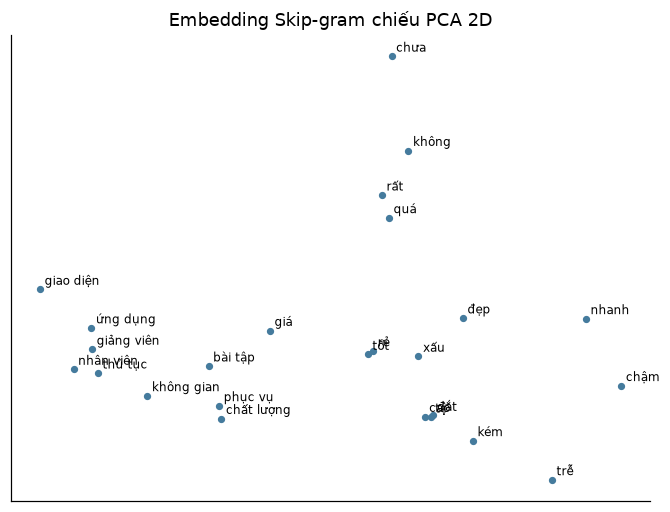

In [10]:
chon = [w for w in ["nhanh", "chậm", "trễ", "tốt", "kém", "tệ", "đẹp", "xấu", "rẻ", "đắt", "cao", "giá",
                    "nhân_viên", "phục_vụ", "thủ_tục", "ứng_dụng", "giao_diện", "bài_tập", "giảng_viên",
                    "món_ăn", "không_gian", "chất_lượng", "không", "chưa", "rất", "quá"] if w in w2i]

X = E_w2v[[w2i[w] for w in chon]]
X = X - X.mean(0)
_, _, Vt2 = np.linalg.svd(X, full_matrices=False)
P = X @ Vt2[:2].T

plt.figure(figsize=(7.5, 5.5))
plt.scatter(P[:, 0], P[:, 1], s=14, c="#457b9d")
for (x, y), w in zip(P, chon):
    plt.annotate(w.replace("_", " "), (x, y), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.title("Embedding Skip-gram chiếu PCA 2D"); plt.xticks([]); plt.yticks([])
plt.show()

## 6. Embedding có tách được khen và chê không?

Ta kiểm chứng định lượng nhận xét ở mục 3.3: lấy một tập tính từ **khen** và một tập tính từ **chê**, đo cosine trung bình *trong cùng nhóm* so với *giữa hai nhóm*. Nếu embedding mã hóa cảm xúc, cosine trong nhóm phải cao hơn hẳn giữa nhóm.

In [11]:
khen = [w for w in ["tốt", "đẹp", "nhanh", "ngon", "rẻ", "hợp_lý", "mượt", "đầy_đủ", "nhiệt_tình", "sạch_sẽ"] if w in w2i]
che  = [w for w in ["kém", "tệ", "chậm", "dở", "đắt", "rối", "bẩn", "sơ_sài", "phức_tạp", "thờ_ơ"] if w in w2i]
print("khen:", khen, "\nchê :", che)

def tb_cos(E, A, B, cung_nhom):
    En = chuan_hoa(E)
    vals = []
    for a in A:
        for b in B:
            if cung_nhom and a == b:
                continue
            vals.append(float(En[w2i[a]] @ En[w2i[b]]))
    return np.mean(vals)

rows = []
for ten, E in [("SVD-PPMI", E_svd), ("Skip-gram", E_w2v)]:
    rows.append({"phương pháp": ten,
                 "cos TB trong nhóm khen": round(tb_cos(E, khen, khen, True), 3),
                 "cos TB trong nhóm chê": round(tb_cos(E, che, che, True), 3),
                 "cos TB giữa khen–chê": round(tb_cos(E, khen, che, False), 3)})
pd.DataFrame(rows)

khen: ['tốt', 'đẹp', 'nhanh', 'ngon', 'rẻ', 'hợp_lý', 'mượt', 'đầy_đủ', 'nhiệt_tình', 'sạch_sẽ'] 
chê : ['kém', 'tệ', 'chậm', 'dở', 'đắt', 'rối', 'bẩn', 'sơ_sài', 'phức_tạp', 'thờ_ơ']


,phương pháp,cos TB trong nhóm khen,cos TB trong nhóm chê,cos TB giữa khen–chê
0,SVD-PPMI,0.502,0.640,0.306
1,Skip-gram,0.466,0.532,0.448


Với SVD-PPMI, cosine **trong nhóm** (≈0,50 nhóm khen, ≈0,64 nhóm chê) cao hơn hẳn **giữa hai nhóm** (≈0,31), nên ở kho này SVD-PPMI *có* gom phần nào theo cảm xúc. Nhưng đừng vội kết luận rằng embedding "hiểu" cảm xúc:

- Nguyên nhân chính nằm ở **dữ liệu tổng hợp**: lời khen thường đi kèm những từ kết như "recommend", "ủng hộ tiếp", còn lời chê đi kèm "thất vọng", "không quay lại". Ngữ cảnh chung đó kéo các tính từ cùng chiều lại gần nhau. Trên bình luận thật, tín hiệu này yếu hơn nhiều.
- Mức tách **khác nhau hẳn giữa hai phương pháp**: với Skip-gram, cosine trong nhóm (≈0,47 khen, ≈0,53 chê) **gần như bằng** giữa nhóm (≈0,45) — hầu như không tách được; và Skip-gram xếp "nhanh" cạnh "chậm". Cùng dữ liệu, hai phương pháp cho hai kết luận khác nhau về "embedding có mã hóa cảm xúc không" — một lý do để **không tin vào một phép đo trên một phương pháp**.
- Vì vậy, các bài toán cảm xúc thường cần **tín hiệu có giám sát** (nhãn), không đủ nếu chỉ dựa vào embedding không giám sát.

## 7. Dùng embedding làm đặc trưng cho phân loại

Cách đơn giản nhất: **vector văn bản = trung bình embedding của các từ**. Sau đó đưa vào Logistic Regression và so với TF-IDF — cùng dữ liệu, cùng tập valid.

In [12]:
def vec_van_ban(text, E):
    toks = [w for s in cau_thanh_tu(text) for w in s if w in w2i]
    return E[[w2i[w] for w in toks]].mean(0) if toks else np.zeros(E.shape[1])

def danh_gia_emb(E, ten):
    Xt = np.array([vec_van_ban(t, E) for t in train["text"]])
    Xv = np.array([vec_van_ban(t, E) for t in valid["text"]])
    sc = StandardScaler().fit(Xt)
    clf = LogisticRegression(max_iter=3000, C=1.0).fit(sc.transform(Xt), train["label"])
    return {"đặc trưng": ten, "macro-F1 valid": round(f1_score(valid["label"], clf.predict(sc.transform(Xv)), average="macro"), 3)}

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
Xt = tfidf.fit_transform(train["text"].map(normalize))
clf = LogisticRegression(C=10, max_iter=3000).fit(Xt, train["label"])
f_tfidf = f1_score(valid["label"], clf.predict(tfidf.transform(valid["text"].map(normalize))), average="macro")

pd.DataFrame([danh_gia_emb(E_svd, f"trung bình embedding SVD-PPMI ({D} chiều)"),
              danh_gia_emb(E_w2v, f"trung bình embedding Skip-gram ({D} chiều)"),
              {"đặc trưng": "TF-IDF 1–2-gram (Bài 3)", "macro-F1 valid": round(f_tfidf, 3)}])

,đặc trưng,macro-F1 valid
0,trung bình embedding SVD-PPMI (32 chiều),0.676
1,trung bình embedding Skip-gram (32 chiều),0.652
2,TF-IDF 1–2-gram (Bài 3),0.886


Embedding trung bình **không** thắng TF-IDF ở đây, và điều đó là bình thường vì:

1. Kho chỉ ~11 nghìn token: embedding học từ rất ít dữ liệu.
2. **Trung bình làm mất thứ tự**: "không tốt" và "tốt không" gần như giống nhau, phủ định bị pha loãng.
3. Embedding không giám sát chỉ mã hóa cảm xúc một cách gián tiếp và nhiễu (mục 6).

Embedding thật sự tỏa sáng khi (a) được học trên kho **rất lớn** rồi tái sử dụng, (b) làm đầu vào cho mô hình có thứ tự (RNN/Transformer, Bài 7–8), và (c) giúp khái quát hóa sang từ **chưa thấy trong dữ liệu có nhãn**. TF-IDF + tuyến tính vẫn là một baseline rất mạnh.

## 8. Hạn chế của embedding tĩnh và hướng đi tiếp

| Hạn chế | Ví dụ | Hướng giải quyết |
|---|---|---|
| **Một vector cho mỗi từ**, bất kể nghĩa | "đá" (cú đá / hòn đá / nước đá), "bàn" (cái bàn / bàn bạc) | Embedding **theo ngữ cảnh** (ELMo → BERT/PhoBERT, Bài 9–10) |
| Từ ngoài từ điển (OOV) | "shipperrr", lỗi chính tả | Embedding subword (fastText), tokenizer BPE (Bài 9) |
| Thiên kiến xã hội trong dữ liệu | vector nghề nghiệp lệch theo giới | Kiểm tra thiên kiến, dữ liệu cân bằng (Bài 14) |
| Tách từ tiếng Việt ảnh hưởng chất lượng | "học_sinh" vs "học" + "sinh" | Dùng đúng đơn vị mà mô hình đã huấn luyện |

**Embedding tiền huấn luyện cho tiếng Việt** mà bạn có thể thử ngoài lớp: *fastText* (bản `cc.vi.300`) và *PhoW2V* của VinAI. Cả hai là tệp lớn (hàng trăm MB đến GB), kiểm tra giấy phép trước khi dùng.

## 9. Tổng kết

- Giả thuyết phân bố: nghĩa của từ ≈ ngữ cảnh của nó.
- Hai đường đi: **đếm + phân rã** (PPMI-SVD) và **học dự đoán** (Skip-gram); hai cách rất gần nhau về mặt toán.
- Embedding đo "thay thế được trong ngữ cảnh": trái nghĩa có thể rất gần nhau.
- Với dữ liệu nhỏ, TF-IDF + tuyến tính khó bị thắng; embedding cần dữ liệu lớn hoặc mô hình có thứ tự.

## Bài tập

1. **(Dễ)** Đổi `WINDOW` thành 1 và 6. Láng giềng của "nhanh" đổi thế nào? Cửa sổ nhỏ nghiêng về cú pháp hay ngữ nghĩa?
2. **(Dễ)** Đổi `D` (số chiều) thành 8 và 100 cho Skip-gram. Macro-F1 ở mục 7 thay đổi ra sao?
3. **(Vừa)** Thêm **trọng số TF-IDF** khi lấy trung bình embedding của văn bản. Có cải thiện không?
4. **(Vừa)** Ghép embedding trung bình với TF-IDF (hstack). Kết quả có tốt hơn riêng TF-IDF không?
5. **(Khó)** Cài **GloVe** hoặc **cải thiện negative sampling** bằng subsampling từ phổ biến (bỏ ngẫu nhiên "rất", "không" với xác suất tỉ lệ tần suất). Láng giềng của từ hiếm có tốt hơn không?

<details>
<summary><b>Gợi ý đáp án</b></summary>

1. Cửa sổ nhỏ (1–2) cho láng giềng *cú pháp* (cùng vai trò: các tính từ); cửa sổ lớn cho láng giềng *chủ đề* (từ cùng bối cảnh).
2. Quá ít chiều (8) mất thông tin; quá nhiều (100) trên kho nhỏ dễ quá khớp. Thường có một vùng ổn định giữa.
3. Trọng số = `idf[w]` rồi chia tổng trọng số; thường giúp nhẹ vì giảm vai trò của từ phổ biến.
4. `scipy.sparse.hstack([Xtfidf, csr_matrix(E_doc)])`; thường ngang hoặc hơi tốt hơn TF-IDF, nhưng cần CV để kết luận.
5. Subsampling: giữ từ w với xác suất `min(1, sqrt(t / f(w)))` (t ≈ 1e-3 trên kho lớn; với kho nhỏ chọn t lớn hơn).
</details>

**Tiếp theo → Bài 6:** mạng nơ-ron cho văn bản với PyTorch — tự học luôn embedding cùng nhiệm vụ.

**Đọc thêm:** Mikolov và cộng sự, *Efficient Estimation of Word Representations in Vector Space* (2013) · Levy & Goldberg, *Neural Word Embedding as Implicit Matrix Factorization* (2014) · [PhoW2V (VinAI)](https://github.com/datquocnguyen/PhoW2V)